# 266건 소송 헤테로 그래프 분석

**목표**: 실제 소송이 일어난 266건의 원고·피고 특허 관계를 헤테로 그래프로 구성하고  
IPC, Citation, Assignee, Co-litigation 등 다양한 관점에서 탐색한다.

**노드 타입**: `patent`, `company`, `ipc`, `case`  
**엣지 타입**: `cites`, `has_ipc`, `owns`, `asserted_in`, `sued`, `co_litigation`

In [2]:
# Cell 1
import re
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import to_hex
import seaborn as sns

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

ROOT   = Path('../..').resolve()   # src/data_266/ → src/ → MANTF-master/
SRC    = ROOT / 'src'
DATA   = ROOT / 'data' / 'samples'

# FAISS 임베딩 (소송 특허 1,331개 100% 커버 확인됨)
FAISS_INDEX = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/faiss.index')
PATENT_IDX  = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/patent_index.parquet')

print('ROOT:', ROOT)
print('FAISS:', FAISS_INDEX.exists(), '/ patent_index:', PATENT_IDX.exists())

ROOT: /home2/jmbyeon/developments/tf_litigation/MANTF-master
FAISS: True / patent_index: True


## 1. 데이터 로드 및 파싱

In [3]:
# Cell 2
raw = pd.read_csv(DATA / 'both_side_patents.csv')
print(f'rows: {len(raw)}, cases: {raw["case_row_id"].nunique()}')
raw.head(3)

rows: 269, cases: 269


,case_row_id,P_patents,D_patents,plaintiffs,defendants
0,731,5897576 | 6088616 | 6366809 | 5700281 | 564557...,5800460 | 6016059 | 5591213 | 5773961 | 623005...,"Cardiac Science, Inc | a Delaware Corporation",Koninklijke Philips Electronics N.V. | Koninkl...
1,930,5287435 | 5519816 | 5386500,6136252 | 6193923 | 6660209 | 6508971 | 6532394,Objet Geometries | Stratasys Inc,3D Systems Inc
2,955,6103286 | 6010729 | 6113963,5632676,"Ecolab, Inc.",FMC Corporation


In [4]:
# Cell 3  — long format
def parse_pipe(s):
    if pd.isna(s):
        return []
    return [x.strip() for x in str(s).split('|') if x.strip()]

rows = []
for _, r in raw.iterrows():
    case_id = r['case_row_id']
    for pat in parse_pipe(r['P_patents']):
        rows.append({'case_row_id': case_id, 'patent_id': pat, 'side': 'plaintiff'})
    for pat in parse_pipe(r['D_patents']):
        rows.append({'case_row_id': case_id, 'patent_id': pat, 'side': 'defendant'})

df_pats = pd.DataFrame(rows)
print(f'Total patent-case pairs: {len(df_pats)}')
print(f'Unique patents: {df_pats["patent_id"].nunique()}')
print(f'Unique cases:   {df_pats["case_row_id"].nunique()}')
df_pats.head()

Total patent-case pairs: 1460
Unique patents: 1331
Unique cases:   269


,case_row_id,patent_id,side
0,731,5897576,plaintiff
1,731,6088616,plaintiff
2,731,6366809,plaintiff
3,731,5700281,plaintiff
4,731,5645571,plaintiff


## 2. 기업명 정규화

In [5]:
# Cell 4  — Company name normalization + merge map

_SUFFIX = re.compile(
    r',?\s*('
    r'incorporated|corporation|company|limited liability company'
    r'|limited liability partnership|limited partnership|limited'
    r'|inc|corp|co|ltd|llc|llp|lp|plc|gmbh|b\.?v|n\.?v|s\.?a|a\.?g|s\.?r\.?l'
    r'|pvt|pte|pty|ab|as|a\/s|oy|oyj|spa|srl|sarl|sas|bv|nv'
    r'|an? (?:delaware|california|new\s+york|new\s+jersey|texas|illinois|florida'
    r'|washington|ohio|michigan|minnesota|pennsylvania|nevada|maryland|virginia'
    r'|massachusetts|colorado|georgia|indiana|wisconsin|arizona|connecticut'
    r'|netherlands|korean?|japanese|german|french|canadian|british|swedish|swiss)'
    r'\s+(?:corporation|limited\s+liability(?:\s+company)?|limited\s+partnership|limited|company)'
    r'|doing business as|terminated.*'
    r')[,.]?\s*$',
    re.IGNORECASE
)
_PREFIX = re.compile(r'^(the|a|an)\s+', re.IGNORECASE)
_JUNK   = re.compile(r'^(does |john doe|unknown|xyz |consolidated civil|consolidating civil|et al)', re.IGNORECASE)

def deep_normalize(name: str) -> str:
    s = str(name).strip()
    s = s.replace('&', 'and')
    s = re.sub(r'[^\w\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip().upper()
    for _ in range(6):
        new = _SUFFIX.sub('', s, count=1).strip()
        if new == s: break
        s = new
    s = _PREFIX.sub('', s).strip()
    return s

_merge_map_path = DATA / 'company_merge_map.csv'
MERGE_MAP = {}
if _merge_map_path.exists():
    _mm = pd.read_csv(_merge_map_path)
    MERGE_MAP = dict(zip(_mm['from'], _mm['to']))
    print(f'Merge map loaded: {len(MERGE_MAP)} entries')

def canonical(name: str) -> str:
    n = deep_normalize(name)
    return MERGE_MAP.get(n, n)

company_rows = []
for _, r in raw.iterrows():
    case_id = r['case_row_id']
    for name in parse_pipe(r['plaintiffs']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': case_id, 'raw_name': name, 'norm_name': cn, 'side': 'plaintiff'})
    for name in parse_pipe(r['defendants']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': case_id, 'raw_name': name, 'norm_name': cn, 'side': 'defendant'})

df_companies = pd.DataFrame(company_rows)

case_companies = []
for case_id, grp in df_companies.groupby('case_row_id'):
    p_names = grp[grp['side'] == 'plaintiff']['norm_name'].tolist()
    d_names = grp[grp['side'] == 'defendant']['norm_name'].tolist()
    case_companies.append({
        'case_row_id':    case_id,
        'main_plaintiff': p_names[0] if p_names else None,
        'main_defendant': d_names[0] if d_names else None,
        'all_plaintiffs': p_names,
        'all_defendants': d_names,
    })

df_cases = pd.DataFrame(case_companies)
print(f'Unique companies (normalized+merge): {df_companies["norm_name"].nunique()}')
print(f'  Plaintiffs: {df_companies[df_companies["side"]=="plaintiff"]["norm_name"].nunique()}')
print(f'  Defendants: {df_companies[df_companies["side"]=="defendant"]["norm_name"].nunique()}')

Merge map loaded: 62 entries
Unique companies (normalized+merge): 1061
  Plaintiffs: 404
  Defendants: 704


In [6]:
# Cell 5  — 정규화 전후 비교 샘플
sample_check = df_companies[['raw_name','norm_name']].drop_duplicates().sample(20, random_state=42)
sample_check

,raw_name,norm_name
545,MSI Computer Corporation,MSI COMPUTER
635,"Pulse Entertainment, Inc.",PULSE ENTERTAINMENT
700,Applied Biotech Inc,APPLIED BIOTECH
226,"Maquet, Inc.",MAQUET
58,"National Express, Inc.",NATIONAL EXPRESS
274,Idenix Pharmaceuticals Inc.,IDENIX PHARMACEUTICALS
794,"Balboa Manufacturing Company, LLC",BALBOA MANUFACTURING
767,WIAV Solutions LLC,WIAV SOLUTIONS
110,ConMed Corporation,CONMED
707,Wampole Laboratories,WAMPOLE LABORATORIES


## 3. 외부 데이터 로드 (IPC / Citation / Assignee)

In [7]:
# Cell 6  — Target patent set
ALL_PATENTS = set(df_pats['patent_id'].unique())
print(f'Target patents: {len(ALL_PATENTS)}')

Target patents: 1331


In [8]:
# Cell 7  — IPC load (subclass level: H04L, G06F, ...)
ipc_raw = pd.read_csv(SRC / 'g_ipc_at_issue.tsv', sep='\t',
                      usecols=['patent_id', 'section', 'ipc_class', 'subclass', 'main_group'],
                      dtype=str)
ipc_raw['patent_id'] = ipc_raw['patent_id'].str.strip()
df_ipc = ipc_raw[ipc_raw['patent_id'].isin(ALL_PATENTS)].copy()
df_ipc['ipc_code'] = (df_ipc['section'].fillna('') +
                      df_ipc['ipc_class'].fillna('') +
                      df_ipc['subclass'].fillna('')).str.strip()
df_ipc = df_ipc[df_ipc['ipc_code'] != ''].drop_duplicates(['patent_id', 'ipc_code'])
print(f'IPC mappings: {len(df_ipc)}, unique IPC codes: {df_ipc["ipc_code"].nunique()}')
df_ipc.head()

IPC mappings: 1545, unique IPC codes: 218


,patent_id,section,ipc_class,subclass,main_group,ipc_code
420,7621968,C,01,D,7,C01D
20277,5173442,H,01,L,21,H01L
37643,8468174,G,06,F,7,G06F
39014,6857878,G,09,B,023,G09B
46505,6701348,G,06,F,13,G06F


In [9]:
# Cell 8  — Citation (litigation patents → all cited, including external)
cit_raw = pd.read_csv(SRC / 'g_us_patent_citation.tsv', sep='\t',
                      usecols=['patent_id', 'citation_patent_id'],
                      dtype=str)
cit_raw['patent_id']          = cit_raw['patent_id'].str.strip()
cit_raw['citation_patent_id'] = cit_raw['citation_patent_id'].str.strip()

df_cit = cit_raw[cit_raw['patent_id'].isin(ALL_PATENTS)].drop_duplicates().copy()

internal_mask   = df_cit['citation_patent_id'].isin(ALL_PATENTS)
df_cit_internal = df_cit[internal_mask]
df_cit_external = df_cit[~internal_mask]
EXTERNAL_CITED  = set(df_cit_external['citation_patent_id'])

print(f'Internal citations (litigation-litigation): {len(df_cit_internal)}')
print(f'External citations (litigation-other):      {len(df_cit_external)}, unique external: {len(EXTERNAL_CITED)}')

Internal citations (litigation-litigation): 803
External citations (litigation-other):      47248, unique external: 21907


In [10]:
# Cell 9  — Assignee: litigation patents (ownership_matched) + external cited (g_assignee)

own_raw = pd.read_csv(DATA / 'patent_ownership_matched_4.csv',
                      usecols=['case_row_id', 'patent_norm', 'final_owner'], dtype=str)
own_raw = own_raw[
    own_raw['case_row_id'].isin({str(c) for c in raw['case_row_id']}) &
    own_raw['final_owner'].notna() &
    own_raw['patent_norm'].notna()
].copy()
own_raw['org_canon'] = own_raw['final_owner'].apply(canonical)
df_asgn_lit = own_raw[own_raw['org_canon'].str.len() > 2].drop_duplicates(
    ['patent_norm', 'org_canon']
).rename(columns={'patent_norm': 'patent_id', 'org_canon': 'org_norm'})[['patent_id', 'org_norm']]

litigation_companies = set(df_companies['norm_name'])

asgn_raw = pd.read_csv(SRC / 'g_assignee_disambiguated.tsv', sep='\t',
                       usecols=['patent_id', 'disambig_assignee_organization'], dtype=str)
asgn_raw['patent_id'] = asgn_raw['patent_id'].str.strip()
asgn_ext = asgn_raw[asgn_raw['patent_id'].isin(EXTERNAL_CITED)].dropna().copy()
asgn_ext['org_canon'] = asgn_ext['disambig_assignee_organization'].apply(canonical)
asgn_ext = asgn_ext[asgn_ext['org_canon'].isin(litigation_companies)].drop_duplicates(
    ['patent_id', 'org_canon']
).rename(columns={'org_canon': 'org_norm'})[['patent_id', 'org_norm']]

df_asgn = pd.concat([df_asgn_lit, asgn_ext], ignore_index=True).drop_duplicates(['patent_id', 'org_norm'])
EXTERNAL_OWNED = set(asgn_ext['patent_id'])

print(f'owns (litigation patents): {len(df_asgn_lit)}')
print(f'owns (external patents):   {len(asgn_ext)},  unique external: {len(EXTERNAL_OWNED)}')
print(f'owns total:                {len(df_asgn)}')
print(f'Company coverage: {df_asgn["org_norm"].nunique()} / {len(litigation_companies)}')

owns (litigation patents): 1335
owns (external patents):   4454,  unique external: 4438
owns total:                5789
Company coverage: 533 / 1061


## 4. 헤테로 그래프 구성 (NetworkX MultiDiGraph)

In [11]:
# Cell 10  — Graph init + nodes
G = nx.MultiDiGraph()

side_info = df_pats.drop_duplicates('patent_id').set_index('patent_id')['side']

for pid in ALL_PATENTS:
    G.add_node(f'pat_{pid}', node_type='patent', label=pid,
               side=side_info.get(pid, 'unknown'), is_litigation=True)

for pid in EXTERNAL_OWNED:
    G.add_node(f'pat_{pid}', node_type='patent', label=pid,
               side='external', is_litigation=False)

for case_id in raw['case_row_id'].unique():
    G.add_node(f'case_{case_id}', node_type='case', label=str(case_id))

for ipc_code in df_ipc['ipc_code'].unique():
    G.add_node(f'ipc_{ipc_code}', node_type='ipc', label=ipc_code)

for name in litigation_companies:
    G.add_node(f'co_{name}', node_type='company', label=name)

print(f'Total nodes: {G.number_of_nodes()}')
print(pd.Series([d['node_type'] for _, d in G.nodes(data=True)]).value_counts())

Total nodes: 7317
patent     5769
company    1061
case        269
ipc         218
Name: count, dtype: int64


In [12]:
# Cell 11  — Edges

for _, r in df_pats.iterrows():
    G.add_edge(f'pat_{r["patent_id"]}', f'case_{r["case_row_id"]}',
               edge_type='asserted_in', side=r['side'])

for _, r in df_ipc.iterrows():
    G.add_edge(f'pat_{r["patent_id"]}', f'ipc_{r["ipc_code"]}',
               edge_type='has_ipc')

for _, r in df_cit.iterrows():
    tgt = r['citation_patent_id']
    if tgt in ALL_PATENTS or tgt in EXTERNAL_OWNED:
        G.add_edge(f'pat_{r["patent_id"]}', f'pat_{tgt}', edge_type='cites')

for _, r in df_asgn.iterrows():
    nid = f'pat_{r["patent_id"]}'
    if nid in G:
        G.add_edge(f'co_{r["org_norm"]}', nid, edge_type='owns')

for _, r in df_cases.iterrows():
    if r['main_plaintiff'] and r['main_defendant']:
        G.add_edge(f'co_{r["main_plaintiff"]}', f'co_{r["main_defendant"]}',
                   edge_type='sued', case_row_id=r['case_row_id'])

for case_id, grp in df_pats.groupby('case_row_id'):
    p_pats = grp[grp['side'] == 'plaintiff']['patent_id'].tolist()
    d_pats = grp[grp['side'] == 'defendant']['patent_id'].tolist()
    for pp in p_pats:
        for dp in d_pats:
            G.add_edge(f'pat_{pp}', f'pat_{dp}',
                       edge_type='co_litigation', case_row_id=case_id)
            G.add_edge(f'pat_{dp}', f'pat_{pp}',
                       edge_type='co_litigation', case_row_id=case_id)

print(f'Total edges: {G.number_of_edges()}')
print(pd.Series([d['edge_type'] for _, _, d in G.edges(data=True)]).value_counts())

Total edges: 23624
cites            9545
owns             5789
co_litigation    5016
has_ipc          1545
asserted_in      1460
sued              269
Name: count, dtype: int64


## 5. 기본 통계 분석

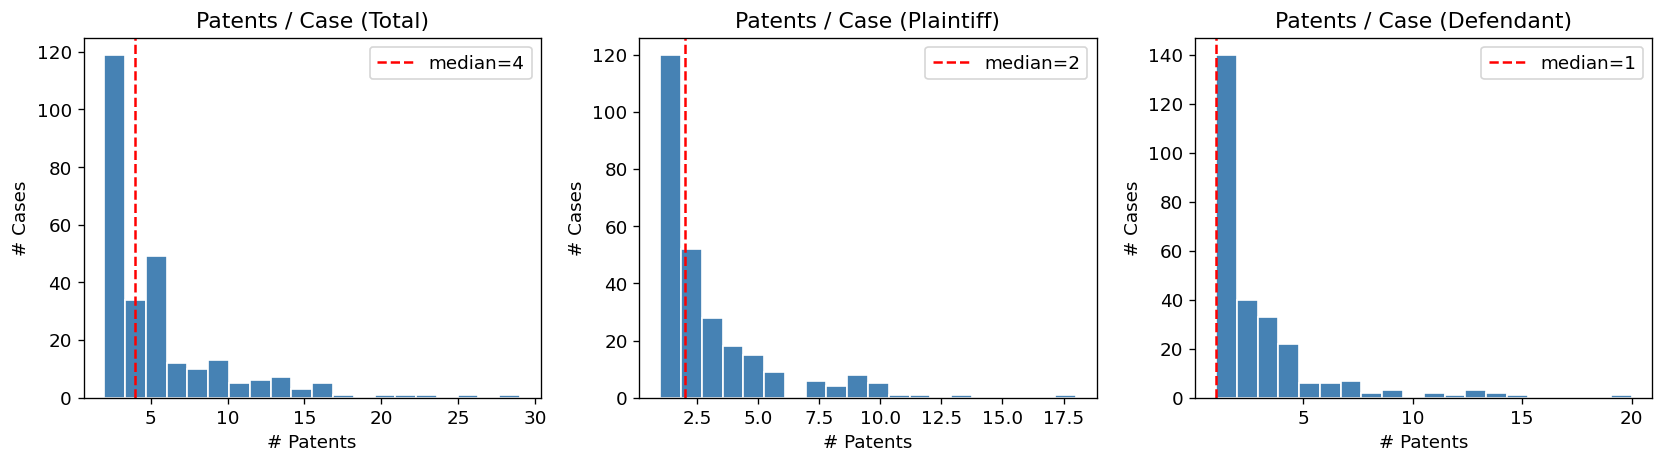

In [13]:
# Cell 12  — Patents per case distribution
pat_per_case = df_pats.groupby('case_row_id')['patent_id'].count()
p_per_case   = df_pats[df_pats['side']=='plaintiff'].groupby('case_row_id')['patent_id'].count()
d_per_case   = df_pats[df_pats['side']=='defendant'].groupby('case_row_id')['patent_id'].count()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, data, title in zip(
    axes,
    [pat_per_case, p_per_case, d_per_case],
    ['Patents / Case (Total)', 'Patents / Case (Plaintiff)', 'Patents / Case (Defendant)']
):
    ax.hist(data, bins=20, color='steelblue', edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel('# Patents')
    ax.set_ylabel('# Cases')
    ax.axvline(data.median(), color='red', linestyle='--', label=f'median={data.median():.0f}')
    ax.legend()
plt.tight_layout()
plt.show()

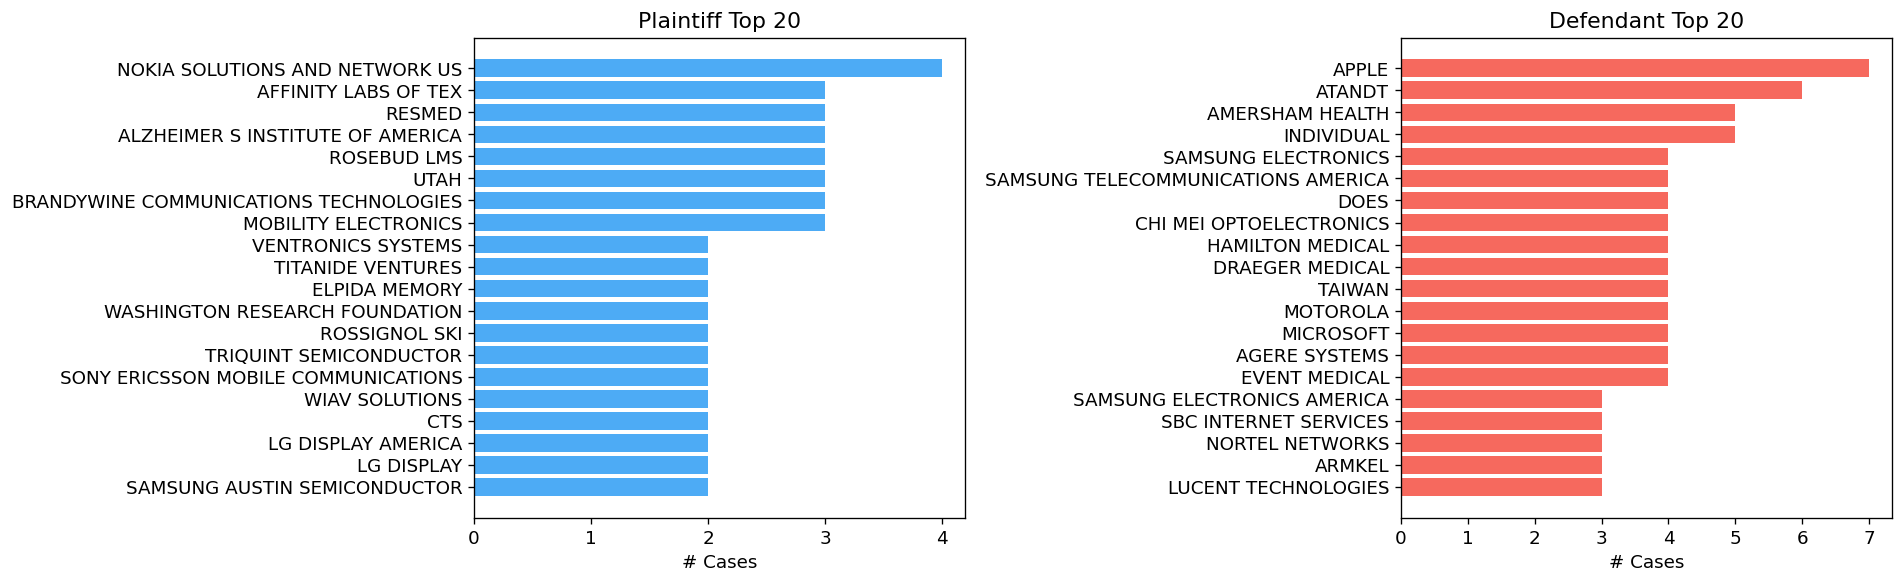

In [14]:
# Cell 13  — Top 20 litigating companies
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_p = df_companies[df_companies['side']=='plaintiff']['norm_name'].value_counts().head(20)
top_d = df_companies[df_companies['side']=='defendant']['norm_name'].value_counts().head(20)

for ax, data, title, color in zip(
    axes,
    [top_p, top_d],
    ['Plaintiff Top 20', 'Defendant Top 20'],
    ['#2196F3', '#F44336']
):
    ax.barh(data.index[::-1], data.values[::-1], color=color, alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel('# Cases')
plt.tight_layout()
plt.show()

## 6. IPC 분석 — 원고 vs 피고 특허 기술 분포

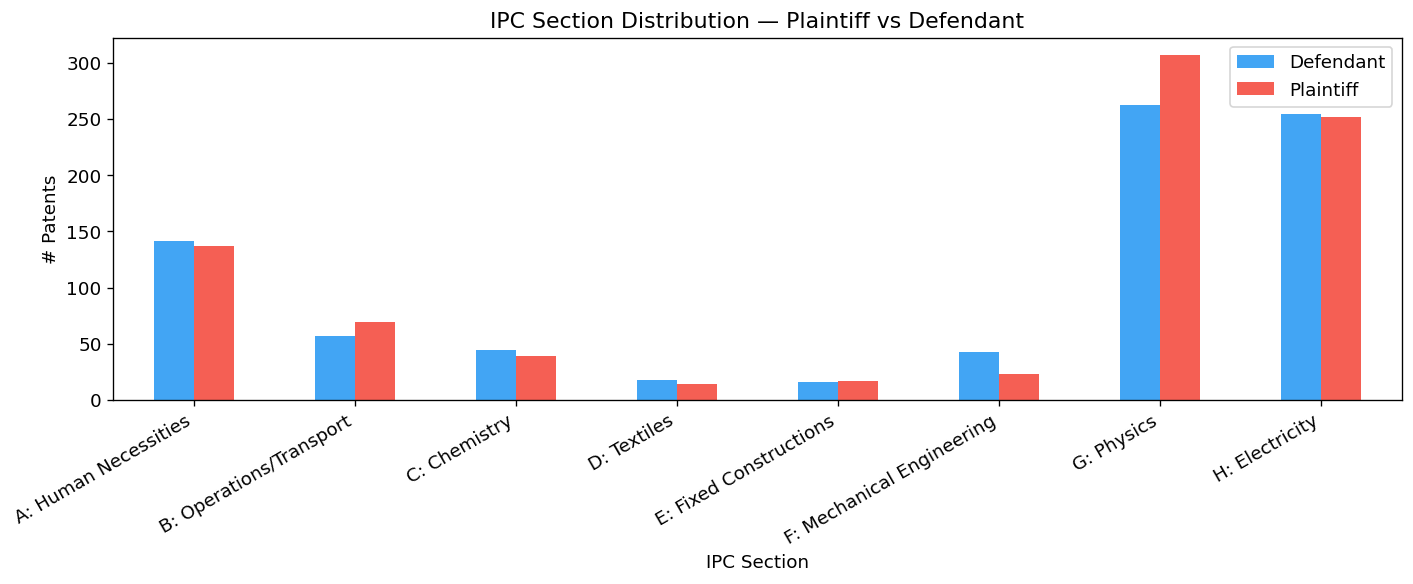

In [15]:
# Cell 14  — IPC section distribution (plaintiff vs defendant)
df_pats_ipc = df_pats.merge(
    df_ipc[['patent_id', 'ipc_code', 'section']].drop_duplicates(),
    on='patent_id', how='left'
)

IPC_SECTION_LABELS = {
    'A': 'A: Human Necessities',
    'B': 'B: Operations/Transport',
    'C': 'C: Chemistry',
    'D': 'D: Textiles',
    'E': 'E: Fixed Constructions',
    'F': 'F: Mechanical Engineering',
    'G': 'G: Physics',
    'H': 'H: Electricity',
}

section_side = df_pats_ipc.dropna(subset=['section']).groupby(['section','side']).size().unstack(fill_value=0)
section_side.index = [IPC_SECTION_LABELS.get(s, s) for s in section_side.index]

section_side.plot(kind='bar', figsize=(12, 5), color=['#2196F3','#F44336'], alpha=0.85)
plt.title('IPC Section Distribution — Plaintiff vs Defendant')
plt.xlabel('IPC Section')
plt.ylabel('# Patents')
plt.xticks(rotation=30, ha='right')
plt.legend(['Defendant', 'Plaintiff'])
plt.tight_layout()
plt.show()

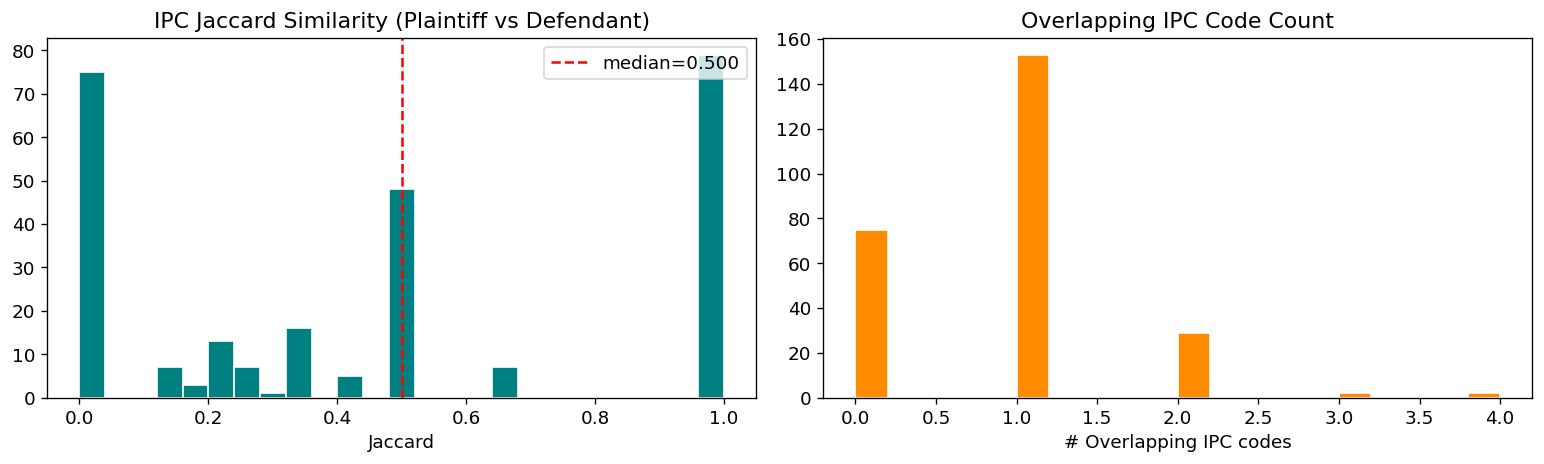

       jaccard  overlap_count
count  261.000        261.000
mean     0.464          0.862
std      0.401          0.693
min      0.000          0.000
25%      0.000          0.000
50%      0.500          1.000
75%      1.000          1.000
max      1.000          4.000


In [16]:
# Cell 15  — IPC Jaccard overlap (plaintiff vs defendant per case)
overlap_rows = []
for case_id, grp in df_pats_ipc.groupby('case_row_id'):
    p_ipc = set(grp[grp['side']=='plaintiff']['ipc_code'].dropna())
    d_ipc = set(grp[grp['side']=='defendant']['ipc_code'].dropna())
    if p_ipc and d_ipc:
        inter = len(p_ipc & d_ipc)
        union = len(p_ipc | d_ipc)
        overlap_rows.append({'case_row_id': case_id,
                             'jaccard': inter / union if union else 0,
                             'overlap_count': inter,
                             'p_ipc': len(p_ipc), 'd_ipc': len(d_ipc)})

df_overlap = pd.DataFrame(overlap_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df_overlap['jaccard'], bins=25, color='teal', edgecolor='white')
axes[0].set_title('IPC Jaccard Similarity (Plaintiff vs Defendant)')
axes[0].set_xlabel('Jaccard')
axes[0].axvline(df_overlap['jaccard'].median(), color='red', linestyle='--',
                label=f"median={df_overlap['jaccard'].median():.3f}")
axes[0].legend()

axes[1].hist(df_overlap['overlap_count'], bins=20, color='darkorange', edgecolor='white')
axes[1].set_title('Overlapping IPC Code Count')
axes[1].set_xlabel('# Overlapping IPC codes')

plt.tight_layout()
plt.show()
print(df_overlap[['jaccard','overlap_count']].describe().round(3))

## 7. Citation 분석 — 소송 쌍 간 인용 경로

In [17]:
# Cell 16  — Citation subgraph (litigation patents only)
G_cit = nx.DiGraph()
G_cit.add_nodes_from(ALL_PATENTS)
for _, r in df_cit_internal.iterrows():
    G_cit.add_edge(r['patent_id'], r['citation_patent_id'])

cite_rows = []
for case_id, grp in df_pats.groupby('case_row_id'):
    p_list = grp[grp['side'] == 'plaintiff']['patent_id'].tolist()
    d_list = grp[grp['side'] == 'defendant']['patent_id'].tolist()
    for pp in p_list:
        for dp in d_list:
            cite_rows.append({
                'case_row_id':   case_id,
                'plaintiff_pat': pp, 'defendant_pat': dp,
                'p_cites_d':     G_cit.has_edge(pp, dp),
                'd_cites_p':     G_cit.has_edge(dp, pp),
            })

df_cite_pairs = pd.DataFrame(cite_rows)
df_cite_pairs['any_direct'] = df_cite_pairs['p_cites_d'] | df_cite_pairs['d_cites_p']

n_with  = df_cite_pairs[df_cite_pairs['any_direct']]['case_row_id'].nunique()
n_total = df_cite_pairs['case_row_id'].nunique()
print(f'Cases with direct citation: {n_with} / {n_total} ({n_with/n_total*100:.1f}%)')
print(f'Plaintiff -> Defendant:     {df_cite_pairs["p_cites_d"].sum()} pairs')
print(f'Defendant -> Plaintiff:     {df_cite_pairs["d_cites_p"].sum()} pairs')

Cases with direct citation: 119 / 269 (44.2%)
Plaintiff -> Defendant:     142 pairs
Defendant -> Plaintiff:     187 pairs


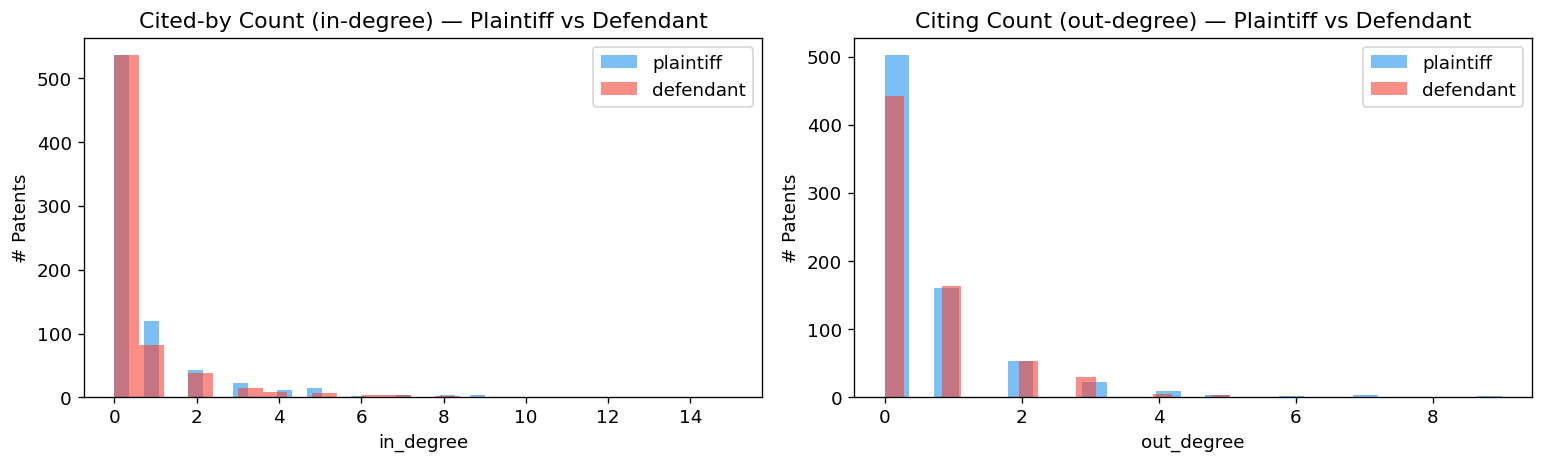

          in_degree                                       out_degree        \
              count  mean   std  min  25%  50%  75%   max      count  mean   
side                                                                         
defendant     701.0  0.54  1.43  0.0  0.0  0.0  0.0  15.0      701.0  0.59   
plaintiff     759.0  0.62  1.35  0.0  0.0  0.0  1.0   9.0      759.0  0.58   

                                          
            std  min  25%  50%  75%  max  
side                                      
defendant  0.98  0.0  0.0  0.0  1.0  7.0  
plaintiff  1.10  0.0  0.0  0.0  1.0  9.0  


In [18]:
# Cell 17  — Citation in/out degree distribution
in_deg  = dict(G_cit.in_degree())
out_deg = dict(G_cit.out_degree())

df_pats['in_degree']  = df_pats['patent_id'].map(in_deg).fillna(0).astype(int)
df_pats['out_degree'] = df_pats['patent_id'].map(out_deg).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in zip(axes, ['in_degree', 'out_degree'],
                          ['Cited-by Count (in-degree)', 'Citing Count (out-degree)']):
    for side, color in [('plaintiff','#2196F3'), ('defendant','#F44336')]:
        vals = df_pats[df_pats['side']==side][col]
        ax.hist(vals.clip(upper=50), bins=25, alpha=0.6, color=color, label=side)
    ax.set_title(f'{title} — Plaintiff vs Defendant')
    ax.set_xlabel(col)
    ax.set_ylabel('# Patents')
    ax.legend()
plt.tight_layout()
plt.show()

print(df_pats.groupby('side')[['in_degree','out_degree']].describe().round(2))

## 8. 네트워크 중심성 분석

In [19]:
# Cell 18  — Co-litigation graph centrality
G_co = nx.Graph()
for u, v, d in G.edges(data=True):
    if d['edge_type'] == 'co_litigation':
        G_co.add_edge(u.replace('pat_', ''), v.replace('pat_', ''),
                      case_row_id=d['case_row_id'])

deg_cent = nx.degree_centrality(G_co)
bet_cent = nx.betweenness_centrality(G_co)

df_cent = pd.DataFrame({
    'patent_id':         list(deg_cent.keys()),
    'degree_centrality': list(deg_cent.values()),
    'betweenness':       [bet_cent.get(p, 0) for p in deg_cent],
}).sort_values('betweenness', ascending=False)

side_map = df_pats.drop_duplicates('patent_id').set_index('patent_id')['side']
df_cent['side'] = df_cent['patent_id'].map(side_map)

print('Top 10 by Betweenness Centrality')
df_cent.head(10)

Top 10 by Betweenness Centrality


,patent_id,degree_centrality,betweenness,side
593,5481721,0.010526,0.001030,plaintiff
245,6493002,0.006767,0.000766,defendant
839,5946647,0.005263,0.000576,defendant
214,5959990,0.014286,0.000327,defendant
209,6496519,0.014286,0.000327,defendant
125,6942426,0.011278,0.000119,plaintiff
57,7079871,0.013534,0.000087,defendant
58,7386001,0.013534,0.000087,defendant
51,7050410,0.013534,0.000087,defendant
53,7200792,0.013534,0.000087,defendant


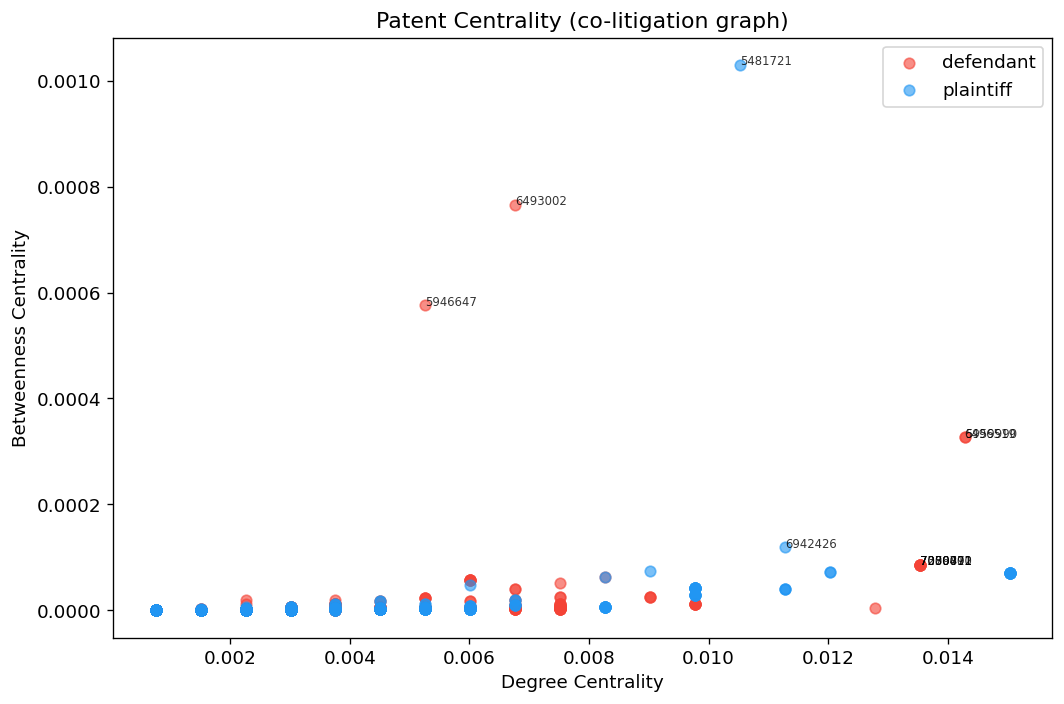

In [20]:
# Cell 19  — Centrality scatter plot
fig, ax = plt.subplots(figsize=(9, 6))
colors = {'plaintiff': '#2196F3', 'defendant': '#F44336'}
for side, grp in df_cent.groupby('side'):
    ax.scatter(grp['degree_centrality'], grp['betweenness'],
               c=colors.get(side, 'gray'), alpha=0.6, s=40, label=side)

for _, row in df_cent.head(10).iterrows():
    ax.annotate(row['patent_id'], (row['degree_centrality'], row['betweenness']),
                fontsize=7, alpha=0.8)

ax.set_xlabel('Degree Centrality')
ax.set_ylabel('Betweenness Centrality')
ax.set_title('Patent Centrality (co-litigation graph)')
ax.legend()
plt.tight_layout()
plt.show()

## 9. 커뮤니티 탐지

In [21]:
# Cell 20  — Community detection (Louvain)
try:
    from community import best_partition
    partition = best_partition(G_co, random_state=42)
    method = 'Louvain'
except ImportError:
    comms = nx.community.greedy_modularity_communities(G_co)
    partition = {node: i for i, comm in enumerate(comms) for node in comm}
    method = 'Greedy Modularity'

df_cent['community'] = df_cent['patent_id'].map(partition)
print(f'[{method}] Communities detected: {df_cent["community"].nunique()}')
df_cent['community'].value_counts().head(10)

[Greedy Modularity] Communities detected: 235


community
1     27
0     27
2     26
3     23
4     21
5     20
6     20
7     18
10    16
8     16
Name: count, dtype: int64

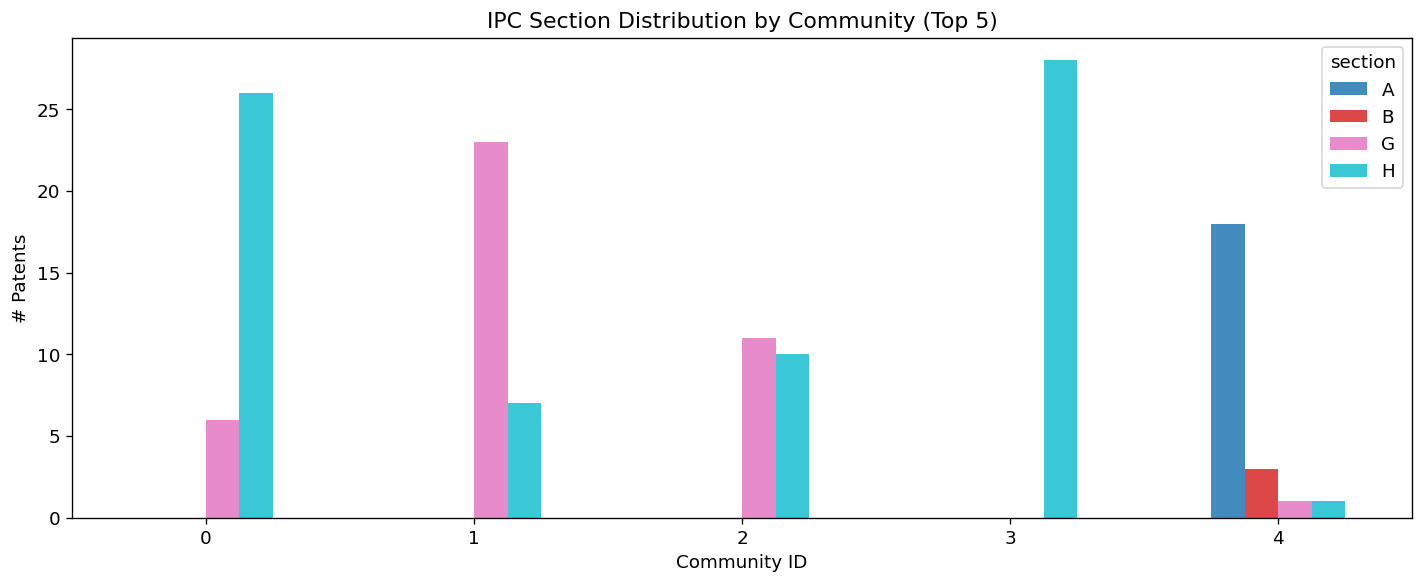

In [22]:
# Cell 21  — IPC distribution per community (top 5)
top_comms = df_cent['community'].value_counts().head(5).index.tolist()

comm_ipc_rows = []
for comm in top_comms:
    pats_in_comm = df_cent[df_cent['community'] == comm]['patent_id'].tolist()
    for sec in df_ipc[df_ipc['patent_id'].isin(pats_in_comm)]['section'].dropna():
        comm_ipc_rows.append({'community': comm, 'section': sec})

if comm_ipc_rows:
    df_comm_ipc = pd.DataFrame(comm_ipc_rows)
    pivot = df_comm_ipc.groupby(['community','section']).size().unstack(fill_value=0)
    pivot.plot(kind='bar', figsize=(12, 5), colormap='tab10', alpha=0.85)
    plt.title('IPC Section Distribution by Community (Top 5)')
    plt.xlabel('Community ID')
    plt.ylabel('# Patents')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 10. PyVis 인터랙티브 시각화

In [23]:
# Cell 22  — PyVis 설치 확인
try:
    from pyvis.network import Network
    print('pyvis OK')
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pyvis', '-q'])
    from pyvis.network import Network
    print('pyvis installed')

pyvis OK


In [24]:
# Cell 23  — PyVis: hetero graph (top N cases)
from pyvis.network import Network
from IPython.display import HTML

VIZ_CASES = 30

NODE_COLORS = {
    'patent_plaintiff': '#2196F3',
    'patent_defendant': '#F44336',
    'company':          '#4CAF50',
    'ipc':              '#FF9800',
    'case':             '#9C27B0',
}
EDGE_COLORS = {
    'asserted_in':  '#888888',
    'has_ipc':      '#FF9800',
    'cites':        '#03A9F4',
    'owns':         '#4CAF50',
    'sued':         '#F44336',
    'co_litigation':'#9C27B0',
}

top_case_ids = pat_per_case.sort_values(ascending=False).head(VIZ_CASES).index.tolist()
case_pats    = df_pats[df_pats['case_row_id'].isin(top_case_ids)]
viz_patents  = set(case_pats['patent_id'])

net = Network(height='750px', width='100%', bgcolor='#1a1a2e', font_color='white',
              notebook=True, directed=True, cdn_resources='in_line')
net.set_options("""
{
  "physics": {"forceAtlas2Based": {"gravitationalConstant": -50, "springLength": 100},
              "solver": "forceAtlas2Based", "stabilization": {"iterations": 150}},
  "edges":   {"smooth": {"type": "continuous"}, "arrows": {"to": {"enabled": true, "scaleFactor": 0.5}}}
}
""")

added_nodes = set()

def add_node(node_id, label, color, size=10, title=''):
    if node_id not in added_nodes:
        net.add_node(node_id, label=label, color=color, size=int(size), title=title)
        added_nodes.add(node_id)

for cid in top_case_ids:
    add_node(f'case_{cid}', f'Case {cid}', NODE_COLORS['case'], size=18, title=f'Case {cid}')

side_map2 = case_pats.drop_duplicates('patent_id').set_index('patent_id')['side']
for pid in viz_patents:
    side  = side_map2.get(pid, 'unknown')
    color = NODE_COLORS.get(f'patent_{side}', '#aaaaaa')
    add_node(f'pat_{pid}', pid, color, size=10, title=f'Patent {pid} ({side})')

for _, r in case_pats.iterrows():
    net.add_edge(f'pat_{r["patent_id"]}', f'case_{r["case_row_id"]}',
                 color=EDGE_COLORS['asserted_in'], width=1, title='asserted_in')

viz_ipc = df_ipc[df_ipc['patent_id'].isin(viz_patents)]
for ipc_code in viz_ipc['ipc_code'].unique():
    add_node(f'ipc_{ipc_code}', ipc_code, NODE_COLORS['ipc'], size=8, title=f'IPC {ipc_code}')
for _, r in viz_ipc.iterrows():
    net.add_edge(f'pat_{r["patent_id"]}', f'ipc_{r["ipc_code"]}',
                 color=EDGE_COLORS['has_ipc'], width=1, title='has_ipc')

viz_cit = df_cit[df_cit['patent_id'].isin(viz_patents) &
                 df_cit['citation_patent_id'].isin(viz_patents)]
for _, r in viz_cit.iterrows():
    net.add_edge(f'pat_{r["patent_id"]}', f'pat_{r["citation_patent_id"]}',
                 color=EDGE_COLORS['cites'], width=2, title='cites')

viz_asgn = df_asgn[df_asgn['patent_id'].isin(viz_patents)]
for name in viz_asgn['org_norm'].unique():
    add_node(f'co_{name}', name[:20], NODE_COLORS['company'], size=14, title=name)
for _, r in viz_asgn.iterrows():
    net.add_edge(f'co_{r["org_norm"]}', f'pat_{r["patent_id"]}',
                 color=EDGE_COLORS['owns'], width=1, title='owns')

viz_cases_df = df_cases[df_cases['case_row_id'].isin(top_case_ids)]
for _, r in viz_cases_df.iterrows():
    if r['main_plaintiff'] and r['main_defendant']:
        add_node(f'co_{r["main_plaintiff"]}', r['main_plaintiff'][:20], NODE_COLORS['company'], size=14)
        add_node(f'co_{r["main_defendant"]}', r['main_defendant'][:20], NODE_COLORS['company'], size=14)
        net.add_edge(f'co_{r["main_plaintiff"]}', f'co_{r["main_defendant"]}',
                     color=EDGE_COLORS['sued'], width=3, title=f'sued (case {r["case_row_id"]})')

out_path = SRC / 'viz_266_hetero.html'
net.save_graph(str(out_path))
print(f'Saved: {out_path}')
HTML(str(out_path))

Saved: /home2/jmbyeon/developments/tf_litigation/MANTF-master/src/viz_266_hetero.html


In [25]:
# Cell 24  — PyVis: company litigation network (sued edges only)
net2 = Network(height='600px', width='100%', bgcolor='#1a1a2e', font_color='white',
               notebook=True, directed=True, cdn_resources='in_line')
net2.set_options("""
{"physics": {"barnesHut": {"gravitationalConstant": -8000, "springLength": 150},
             "stabilization": {"iterations": 200}}}
""")

p_counts = df_companies[df_companies['side']=='plaintiff']['norm_name'].value_counts()
d_counts = df_companies[df_companies['side']=='defendant']['norm_name'].value_counts()

added2 = set()
for _, r in df_cases.iterrows():
    p, d = r['main_plaintiff'], r['main_defendant']
    if not p or not d:
        continue
    for name, counts, color in [(p, p_counts, '#2196F3'), (d, d_counts, '#F44336')]:
        if name not in added2:
            sz = int(min(5 + counts.get(name, 1) * 4, 40))
            net2.add_node(name, label=name[:25], color=color, size=sz, title=name)
            added2.add(name)
    net2.add_edge(p, d, color='#FF9800', width=2, title=f'Case {r["case_row_id"]}')

out2 = SRC / 'viz_266_companies.html'
net2.save_graph(str(out2))
print(f'Saved: {out2}')
HTML(str(out2))

Saved: /home2/jmbyeon/developments/tf_litigation/MANTF-master/src/viz_266_companies.html


## 11. co-litigation 패턴 분석

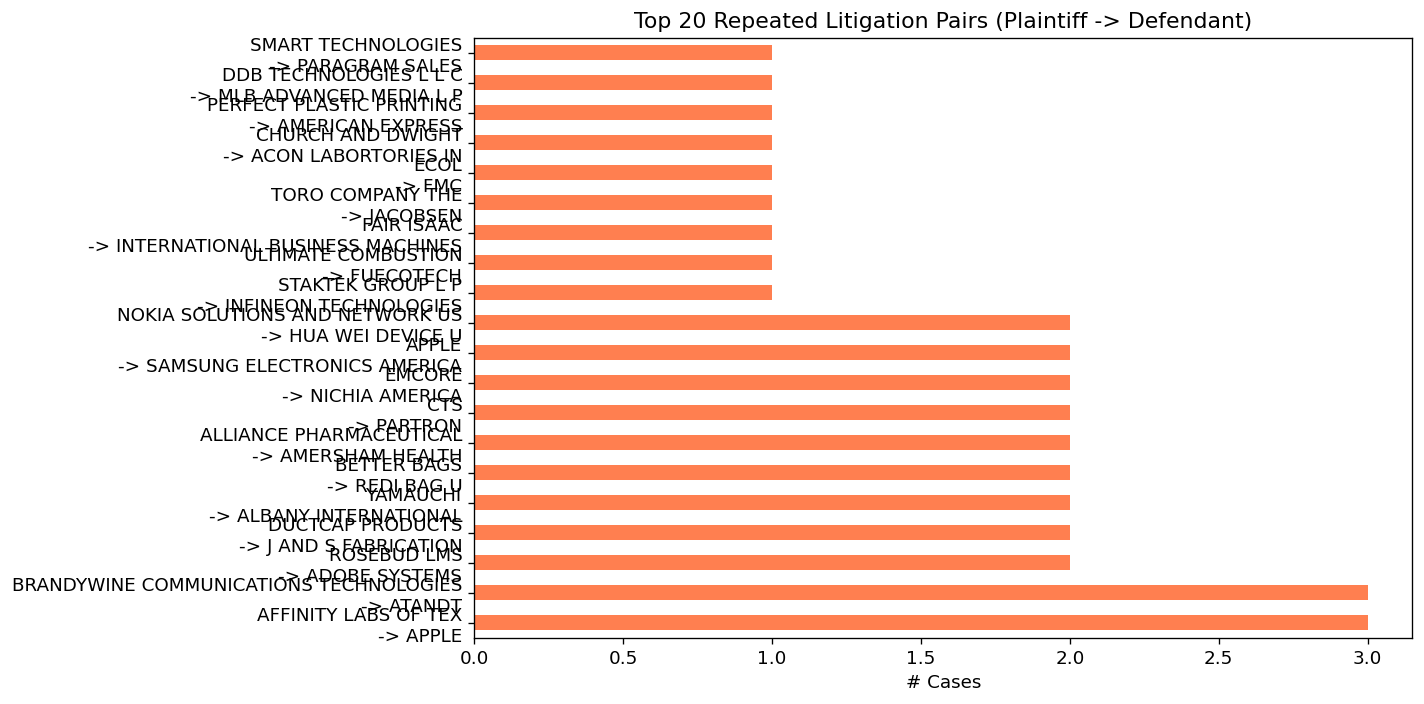

In [26]:
# Cell 25  — Repeated litigation pairs (plaintiff -> defendant)
sued_pairs = []
for _, r in df_cases.iterrows():
    if r['main_plaintiff'] and r['main_defendant']:
        sued_pairs.append((r['main_plaintiff'], r['main_defendant']))

pair_counts = pd.Series(sued_pairs).value_counts().head(20)
pair_counts.index = [f"{p}\n-> {d}" for p, d in pair_counts.index]

plt.figure(figsize=(12, 6))
pair_counts.plot(kind='barh', color='coral')
plt.title('Top 20 Repeated Litigation Pairs (Plaintiff -> Defendant)')
plt.xlabel('# Cases')
plt.tight_layout()
plt.show()

In [27]:
# Cell 26  — Cases where a company appears on both sides
overlap_cases = []
for _, r in df_cases.iterrows():
    p_set = set(r['all_plaintiffs'])
    d_set = set(r['all_defendants'])
    both  = p_set & d_set
    if both:
        overlap_cases.append({'case_row_id': r['case_row_id'], 'both_sides': list(both)})

print(f'Cases with company on both sides: {len(overlap_cases)}')
if overlap_cases:
    pd.DataFrame(overlap_cases).head(10)

Cases with company on both sides: 2


## 12. 그래프 요약 및 저장

In [28]:
# Cell 27  — Graph summary
print('=' * 50)
print('Heterogeneous Graph Summary')
print('=' * 50)
type_counts      = pd.Series([d['node_type'] for _, d in G.nodes(data=True)]).value_counts()
edge_type_counts = pd.Series([d['edge_type'] for _, _, d in G.edges(data=True)]).value_counts()
print('\n[Nodes]')
print(type_counts.to_string())
print(f'  Total: {G.number_of_nodes()}')
print('\n[Edges]')
print(edge_type_counts.to_string())
print(f'  Total: {G.number_of_edges()}')
print()
print(f'IPC-mapped patents:    {df_ipc["patent_id"].nunique()} / {len(ALL_PATENTS)}')
print(f'Citation pairs:        {len(df_cit)}')
print(f'Assignee-mapped pats:  {df_asgn["patent_id"].nunique()} / {len(ALL_PATENTS)}')

Heterogeneous Graph Summary

[Nodes]
patent     5769
company    1061
case        269
ipc         218
  Total: 7317

[Edges]
cites            9545
owns             5789
co_litigation    5016
has_ipc          1545
asserted_in      1460
sued              269
  Total: 23624

IPC-mapped patents:    1296 / 1331
Citation pairs:        48051
Assignee-mapped pats:  5769 / 1331


In [29]:
# Cell 28  — Export GraphML (Gephi compatible)
G_simple = nx.DiGraph()
for node, data in G.nodes(data=True):
    G_simple.add_node(node, **{k: str(v) for k, v in data.items()})
for u, v, data in G.edges(data=True):
    if G_simple.get_edge_data(u, v) is None:
        G_simple.add_edge(u, v, **{k: str(v2) for k, v2 in data.items()})

out_gml = SRC / 'graph_266.graphml'
nx.write_graphml(G_simple, str(out_gml))
print(f'GraphML saved: {out_gml}')
print('Open in Gephi: File -> Open -> graph_266.graphml')

GraphML saved: /home2/jmbyeon/developments/tf_litigation/MANTF-master/src/graph_266.graphml
Open in Gephi: File -> Open -> graph_266.graphml


## 13. Graphistry 시각화 (클라우드 인터랙티브)

- `g.plot()` 실행 시 `hub.graphistry.com`에 업로드 → 브라우저 URL로 열림
- Free tier는 **public only** (`mode='public'` 필수)
- 노드 클릭/드래그/필터/검색 모두 지원, 수천 노드도 GPU 가속으로 실시간

In [30]:
# Cell 29  — Graphistry register
import subprocess, sys
try:
    import graphistry
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'graphistry', '-q'])
    import graphistry

graphistry.register(
    api=3,
    protocol='https',
    server='hub.graphistry.com',
    username='jungmin',
    password='wjdalsvnf3!',
)
graphistry.privacy(mode='public')
print('graphistry', graphistry.__version__, 'registered')

graphistry 0.57.0 registered


In [31]:
# Cell 30  — Graphistry node/edge DataFrames
import struct

def hex_to_int32(hex_color: str) -> int:
    h = hex_color.lstrip('#')
    r, g, b = int(h[0:2], 16), int(h[2:4], 16), int(h[4:6], 16)
    packed = struct.pack('I', (r << 24) | (g << 16) | (b << 8) | 0xFF)
    return struct.unpack('i', packed)[0]

NODE_COLOR_MAP = {
    'patent_plaintiff': '#2196F3',
    'patent_defendant': '#F44336',
    'patent_external':  '#AB47BC',
    'patent_unknown':   '#9E9E9E',
    'company':          '#4CAF50',
    'ipc':              '#FF9800',
    'case':             '#E91E63',
}
EDGE_COLOR_MAP = {
    'asserted_in':   '#9E9E9E',
    'has_ipc':       '#FF9800',
    'cites':         '#00BCD4',
    'owns':          '#4CAF50',
    'sued':          '#F44336',
    'co_litigation': '#9C27B0',
}
EDGE_WIDTH_MAP = {
    'asserted_in': 1, 'has_ipc': 1, 'cites': 2,
    'owns': 2, 'sued': 4, 'co_litigation': 3,
}
NODE_SIZE_MAP = {'patent': 1, 'company': 4, 'ipc': 1, 'case': 3}

side_info = df_pats.drop_duplicates('patent_id').set_index('patent_id')['side']

node_rows = []
for nid, data in G.nodes(data=True):
    nt  = data['node_type']
    lbl = data.get('label', nid)
    if nt == 'patent':
        side  = side_info.get(lbl, data.get('side', 'unknown'))
        hex_c = NODE_COLOR_MAP.get(f'patent_{side}', NODE_COLOR_MAP['patent_unknown'])
        tip   = f'Patent {lbl} ({side})'
    else:
        hex_c = NODE_COLOR_MAP.get(nt, '#aaaaaa')
        tip   = f'{nt}: {lbl}'
    node_rows.append({'id': nid, 'label': lbl[:30], 'node_type': nt,
                      'color': hex_to_int32(hex_c),
                      'size': NODE_SIZE_MAP.get(nt, 1), 'tooltip': tip})

df_gn = pd.DataFrame(node_rows)

edge_rows = []
for u, v, d in G.edges(data=True):
    et = d['edge_type']
    edge_rows.append({'src': u, 'dst': v, 'edge_type': et,
                      'color': hex_to_int32(EDGE_COLOR_MAP.get(et, '#888888')),
                      'width': EDGE_WIDTH_MAP.get(et, 1)})

df_ge = pd.DataFrame(edge_rows)
print(f'Nodes: {len(df_gn)}, Edges: {len(df_ge)}')
print(df_ge['edge_type'].value_counts())

Nodes: 7317, Edges: 23624
edge_type
cites            9545
owns             5789
co_litigation    5016
has_ipc          1545
asserted_in      1460
sued              269
Name: count, dtype: int64


In [32]:
# Cell 31  — Graphistry view 1: hetero graph (co_litigation + cites + sued + owns)
SHOW_EDGE_TYPES = {'co_litigation', 'cites', 'sued', 'owns'}
df_ge_viz = df_ge[df_ge['edge_type'].isin(SHOW_EDGE_TYPES)]
df_gn_viz = df_gn[df_gn['id'].isin(set(df_ge_viz['src']) | set(df_ge_viz['dst']))]

g = (
    graphistry
    .nodes(df_gn_viz, 'id')
    .edges(df_ge_viz, 'src', 'dst')
    .bind(point_label='label', point_color='color', point_size='size',
          point_title='tooltip', edge_color='color', edge_weight='width', edge_title='edge_type')
    .settings(url_params={'play': 3000, 'strongGravity': True})
)
url = g.plot(render=False)
print('URL:', url)
g.plot()

URL: https://hub.graphistry.com/graph/graph.html?dataset=b0f08dfe014741d2af127c2e62f115e2&type=arrow&viztoken=1645d331-e624-4df5-90e9-62b86af9da49&usertag=f1dde34c-pygraphistry-0.57.0&splashAfter=1782971533&info=true&play=3000&strongGravity=True


In [33]:
# Cell 32  — Graphistry view 2: company litigation network (sued edges only)
df_ge_sued = df_ge[df_ge['edge_type'] == 'sued']
sued_ids   = set(df_ge_sued['src']) | set(df_ge_sued['dst'])
df_gn_sued = df_gn[df_gn['id'].isin(sued_ids)].copy()

sue_count = df_ge_sued.groupby('src').size().rename('sue_out')
def_count = df_ge_sued.groupby('dst').size().rename('def_in')
df_gn_sued = df_gn_sued.join(sue_count, on='id').join(def_count, on='id')
df_gn_sued['size'] = (
    (df_gn_sued['sue_out'].fillna(0) + df_gn_sued['def_in'].fillna(0)) * 3 + 10
).clip(upper=60)

g2 = (
    graphistry
    .nodes(df_gn_sued, 'id')
    .edges(df_ge_sued, 'src', 'dst')
    .bind(point_label='label', point_color='color', point_size='size',
          point_title='tooltip', edge_color='color', edge_weight='width', edge_title='edge_type')
    .settings(url_params={'play': 5000})
)
url2 = g2.plot(render=False)
print('Litigation network URL:', url2)
g2.plot()

Litigation network URL: https://hub.graphistry.com/graph/graph.html?dataset=4d47449c7392431aa25dc1175c3553bb&type=arrow&viztoken=2b576516-df7f-48f6-82a3-426a7120fe04&usertag=f1dde34c-pygraphistry-0.57.0&splashAfter=1782971544&info=true&play=5000


In [ ]:
# Cell 33  — Graphistry view 3: single case subgraph
TARGET_CASE = raw['case_row_id'].iloc[0]  # change to desired case_row_id

case_node_id = f'case_{TARGET_CASE}'
case_pat_ids = {f'pat_{r["patent_id"]}'
                for _, r in df_pats[df_pats['case_row_id'] == TARGET_CASE].iterrows()}
focus_ids = {case_node_id} | case_pat_ids

df_ge_sub = df_ge[df_ge['src'].isin(focus_ids) | df_ge['dst'].isin(focus_ids)]
sub_ids   = set(df_ge_sub['src']) | set(df_ge_sub['dst'])
df_gn_sub = df_gn[df_gn['id'].isin(sub_ids)]

g3 = (
    graphistry
    .nodes(df_gn_sub, 'id')
    .edges(df_ge_sub, 'src', 'dst')
    .bind(point_label='label', point_color='color', point_size='size',
          point_title='tooltip', edge_color='color', edge_weight='width', edge_title='edge_type')
)
print(f'Case {TARGET_CASE} subgraph: {len(df_gn_sub)} nodes, {len(df_ge_sub)} edges')
g3.plot()

Case 731 subgraph: 32 nodes, 304 edges


## 14. Plaintiff vs Defendant Patent Relationship Analysis

- **Citation direction**: Does plaintiff patent cite defendant's (or vice versa)?
- **Hop distance**: If no direct citation, how many steps apart in the citation graph?
- **Embedding similarity**: Are the two sides technically similar (BGE-M3 cosine similarity)?

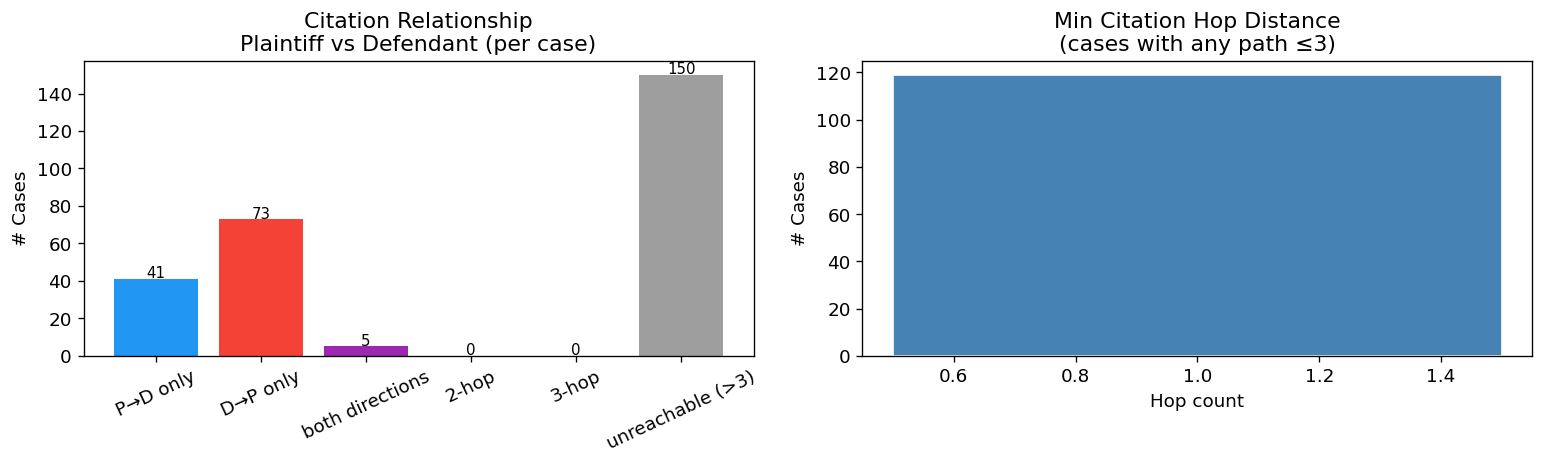

direction
unreachable (>3)    150
D→P only             73
P→D only             41
both directions       5
Name: count, dtype: int64


In [35]:
# Cell 35  — Citation direction & hop distance: plaintiff ↔ defendant
cite_dir_rows = []
for case_id, grp in df_pats.groupby('case_row_id'):
    p_list = grp[grp['side'] == 'plaintiff']['patent_id'].tolist()
    d_list = grp[grp['side'] == 'defendant']['patent_id'].tolist()

    p2d = sum(1 for pp in p_list for dp in d_list if G_cit.has_edge(pp, dp))
    d2p = sum(1 for pp in p_list for dp in d_list if G_cit.has_edge(dp, pp))

    min_hop = None
    if p2d > 0 or d2p > 0:
        min_hop = 1
    else:
        d_set = set(d_list)
        p_set = set(p_list)
        for src, targets in [(pp, d_set) for pp in p_list] + [(dp, p_set) for dp in d_list]:
            try:
                lengths = nx.single_source_shortest_path_length(G_cit, src, cutoff=3)
                for tgt in targets:
                    if tgt in lengths:
                        h = lengths[tgt]
                        if min_hop is None or h < min_hop:
                            min_hop = h
            except nx.NodeNotFound:
                pass

    def _label(p2d, d2p, hop):
        if p2d > 0 and d2p > 0: return 'both directions'
        if p2d > 0: return 'P→D only'
        if d2p > 0: return 'D→P only'
        if hop == 2: return '2-hop'
        if hop == 3: return '3-hop'
        return 'unreachable (>3)'

    cite_dir_rows.append({
        'case_row_id': case_id,
        'p_to_d': p2d, 'd_to_p': d2p,
        'min_hop': min_hop,
        'direction': _label(p2d, d2p, min_hop),
    })

df_cite_dir = pd.DataFrame(cite_dir_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

order = ['P→D only', 'D→P only', 'both directions', '2-hop', '3-hop', 'unreachable (>3)']
counts = df_cite_dir['direction'].value_counts().reindex(order, fill_value=0)
colors = ['#2196F3','#F44336','#9C27B0','#FF9800','#FFC107','#9E9E9E']
axes[0].bar(counts.index, counts.values, color=colors)
axes[0].set_title('Citation Relationship\nPlaintiff vs Defendant (per case)')
axes[0].set_ylabel('# Cases')
axes[0].tick_params(axis='x', rotation=25)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontsize=9)

hop_df = df_cite_dir['min_hop'].dropna()
if len(hop_df):
    axes[1].hist(hop_df, bins=range(1, int(hop_df.max()) + 2),
                 color='steelblue', edgecolor='white', align='left')
    axes[1].set_title('Min Citation Hop Distance\n(cases with any path ≤3)')
    axes[1].set_xlabel('Hop count')
    axes[1].set_ylabel('# Cases')

plt.tight_layout()
plt.show()
print(df_cite_dir['direction'].value_counts())

Embeddings loaded: 1331 / 1331 patents


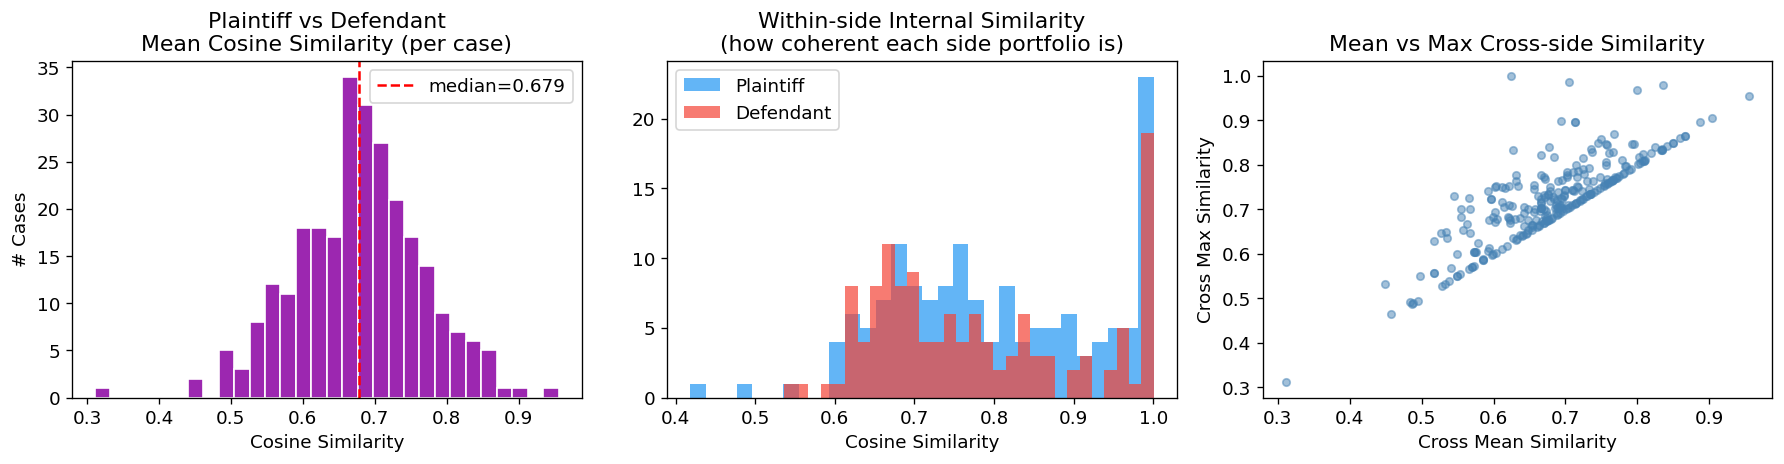

       cross_mean  cross_max  p_internal_mean  d_internal_mean
count     269.000    269.000          149.000          129.000
mean        0.678      0.721            0.801            0.780
std         0.090      0.095            0.133            0.131
min         0.311      0.311            0.419            0.536
25%         0.622      0.674            0.694            0.674
50%         0.679      0.724            0.780            0.752
75%         0.735      0.774            0.922            0.865
max         0.956      1.000            1.001            1.001


In [36]:
# Cell 36  — Embedding cosine similarity: plaintiff vs defendant per case
import faiss as _faiss

_index     = _faiss.read_index(str(FAISS_INDEX))
_pidx      = pd.read_parquet(PATENT_IDX)
pid_to_fid = dict(zip(_pidx['patent_id'].astype(str).str.strip(), _pidx['faiss_id']))

valid_pids  = [p for p in ALL_PATENTS if p in pid_to_fid]
pid_to_emb  = {p: _index.reconstruct(int(pid_to_fid[p])) for p in valid_pids}
print(f'Embeddings loaded: {len(pid_to_emb)} / {len(ALL_PATENTS)} patents')

def cos_sim(a, b):
    return float(np.dot(a, b))   # already L2-normalized → dot = cosine

sim_rows = []
for case_id, grp in df_pats.groupby('case_row_id'):
    p_embs = [pid_to_emb[p] for p in grp[grp['side']=='plaintiff']['patent_id'] if p in pid_to_emb]
    d_embs = [pid_to_emb[p] for p in grp[grp['side']=='defendant']['patent_id'] if p in pid_to_emb]
    if not p_embs or not d_embs:
        continue

    cross = [cos_sim(pe, de) for pe in p_embs for de in d_embs]
    p_int = [cos_sim(p_embs[i], p_embs[j])
             for i in range(len(p_embs)) for j in range(i+1, len(p_embs))]
    d_int = [cos_sim(d_embs[i], d_embs[j])
             for i in range(len(d_embs)) for j in range(i+1, len(d_embs))]

    sim_rows.append({
        'case_row_id':     case_id,
        'cross_mean':      float(np.mean(cross)),
        'cross_max':       float(np.max(cross)),
        'p_internal_mean': float(np.mean(p_int)) if p_int else float('nan'),
        'd_internal_mean': float(np.mean(d_int)) if d_int else float('nan'),
        'n_p': len(p_embs), 'n_d': len(d_embs),
    })

df_sim = pd.DataFrame(sim_rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_sim['cross_mean'], bins=30, color='#9C27B0', edgecolor='white')
axes[0].axvline(df_sim['cross_mean'].median(), color='red', linestyle='--',
                label=f"median={df_sim['cross_mean'].median():.3f}")
axes[0].set_title('Plaintiff vs Defendant\nMean Cosine Similarity (per case)')
axes[0].set_xlabel('Cosine Similarity')
axes[0].set_ylabel('# Cases')
axes[0].legend()

axes[1].hist(df_sim['p_internal_mean'].dropna(), bins=30, color='#2196F3', alpha=0.7, label='Plaintiff')
axes[1].hist(df_sim['d_internal_mean'].dropna(), bins=30, color='#F44336', alpha=0.7, label='Defendant')
axes[1].set_title('Within-side Internal Similarity\n(how coherent each side portfolio is)')
axes[1].set_xlabel('Cosine Similarity')
axes[1].legend()

axes[2].scatter(df_sim['cross_mean'], df_sim['cross_max'], alpha=0.5, s=20, color='steelblue')
axes[2].set_xlabel('Cross Mean Similarity')
axes[2].set_ylabel('Cross Max Similarity')
axes[2].set_title('Mean vs Max Cross-side Similarity')

plt.tight_layout()
plt.show()
print(df_sim[['cross_mean','cross_max','p_internal_mean','d_internal_mean']].describe().round(3))

In [37]:
total_pairs = sum(
    len(grp[grp['side']=='plaintiff']) * len(grp[grp['side']=='defendant'])
    for _, grp in df_pats.groupby('case_row_id')
)
print(total_pairs)

2508
